<a href="https://colab.research.google.com/github/EeshaNP5741832/EeshaNP5741832-DataScience-GenAI-Submissions/blob/main/7_01_Exploratory_Data_Analysis_Salary_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
In this exercise, you will explore a salary dataset (`EDA-DP.csv`) from the Week 7 Seminar Resources on myWBS. Work through the tasks in order. The setup cell below imports the libraries and allows you to upload the dataset.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving EDA-DP.csv to EDA-DP (1).csv


**Task 1 — Load the data.** Read `EDA-DP.csv` into a pandas DataFrame and display the first few rows.

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('EDA-DP.csv')

In [5]:
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


In [7]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/1bb0K16bqOgjyQuzhUq1xpDBImFn5gz4-M2Oru5VDvKc/edit#gid=0


**Task 2 — Dataset size.** Find the number of rows and columns in the dataset.

In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 16534
Number of columns: 11


**Task 3 — Dataset structure.** Inspect the column names, data types, and number of non-missing values.

In [9]:
# Display column names
print(df.columns)

# Display data types
print(df.dtypes)

# Display non-missing values
print(df.count())

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')
work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: object
work_year             16534
experience_level      16534
employment_type       16534
job_title             16534
salary                16534
salary_currency       16534
salary_in_usd         16534
employee_residence    16534
remote_ratio          16534
company_location      16534
company_size          16534
dtype: int64


**Task 4 — Missing data.** Check how many missing values there are in each column.

In [10]:
# Check missing values in each column
df.isnull().sum()

,0
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


**Task 5 — Missing-data percentages.** Calculate the percentage of missing values for each column. Think about how you would handle missing data if you found any.

In [11]:
# Calculate percentage of missing values in each column
(df.isnull().mean() * 100)

,0
work_year,0.0
experience_level,0.0
employment_type,0.0
job_title,0.0
salary,0.0
salary_currency,0.0
salary_in_usd,0.0
employee_residence,0.0
remote_ratio,0.0
company_location,0.0


**Task 6 — Duplicates.** Find how many rows are exact duplicates and how many are not. Would identical records necessarily be errors in this dataset?

In [12]:
# Count exact duplicate rows
df.duplicated().sum()

np.int64(6421)

In [13]:
# Count non-duplicate rows
(~df.duplicated()).sum()

np.int64(10113)

In [14]:
print("Number of duplicate rows:", df.duplicated().sum())
print("Number of non-duplicate rows:", (~df.duplicated()).sum())

Number of duplicate rows: 6421
Number of non-duplicate rows: 10113


**Task 7 — Summary statistics.** Produce descriptive statistics for the numerical columns. What do the distributions tell you? Note that `salary` may use different currencies, whereas `salary_in_usd` is comparable across records.

In [15]:
# Descriptive statistics for numerical columns
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,16534.000000,1.653400e+04,16534.000000,16534.000000
mean,2023.226866,1.637270e+05,149686.777973,32.003750
std,0.713558,3.402057e+05,68505.293156,46.245158
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2023.000000,1.017630e+05,101125.000000,0.000000
50%,2023.000000,1.422000e+05,141300.000000,0.000000
75%,2024.000000,1.872000e+05,185900.000000,100.000000
max,2024.000000,3.040000e+07,800000.000000,100.000000


In [16]:
# Summary statistics for salary and salary_in_usd
df[['salary', 'salary_in_usd']].describe()

,salary,salary_in_usd
count,1.653400e+04,16534.000000
mean,1.637270e+05,149686.777973
std,3.402057e+05,68505.293156
min,1.400000e+04,15000.000000
25%,1.017630e+05,101125.000000
50%,1.422000e+05,141300.000000
75%,1.872000e+05,185900.000000
max,3.040000e+07,800000.000000


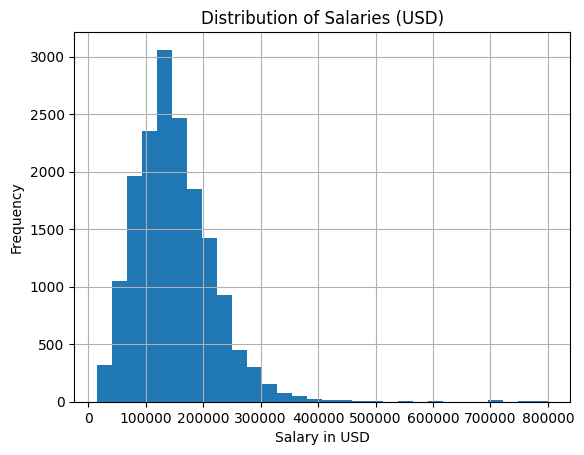

In [17]:
import matplotlib.pyplot as plt

df['salary_in_usd'].hist(bins=30)

plt.title('Distribution of Salaries (USD)')
plt.xlabel('Salary in USD')
plt.ylabel('Frequency')
plt.show()

### Visualising the Data

**Task 8 — Bar chart.** Create a bar chart comparing the **average salary in USD** across experience levels (`EN`, `MI`, `SE`, `EX`). Add clear axis labels and a title. Which group has the highest average?

In [18]:
# Calculate average salary for each experience level
avg_salary = df.groupby('experience_level')['salary_in_usd'].mean()

print(avg_salary)

experience_level
EN     92327.413585
EX    195264.281437
MI    125923.131253
SE    163662.826148
Name: salary_in_usd, dtype: float64


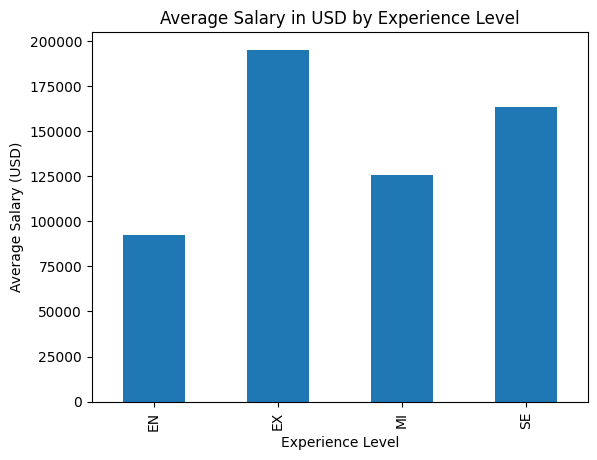

In [19]:
import matplotlib.pyplot as plt

# Create bar chart
avg_salary.plot(kind='bar')

# Add title and axis labels
plt.title('Average Salary in USD by Experience Level')
plt.xlabel('Experience Level')
plt.ylabel('Average Salary (USD)')

# Display chart
plt.show()

In [20]:
avg_salary.idxmax()

'EX'

In [21]:
print("Highest average salary:", avg_salary.max())
print("Experience level:", avg_salary.idxmax())

Highest average salary: 195264.28143712576
Experience level: EX


**Task 9 — Scatter plot.** Make a scatter plot of `work_year` against `salary_in_usd`. Label the axes. What patterns do you notice? Are any points difficult to distinguish because they overlap?

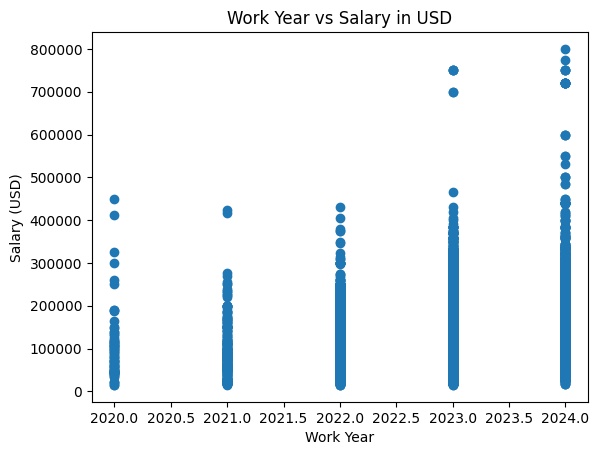

In [22]:
import matplotlib.pyplot as plt

# Create scatter plot
plt.scatter(df['work_year'], df['salary_in_usd'])

# Add title and axis labels
plt.title('Work Year vs Salary in USD')
plt.xlabel('Work Year')
plt.ylabel('Salary (USD)')

# Display plot
plt.show()

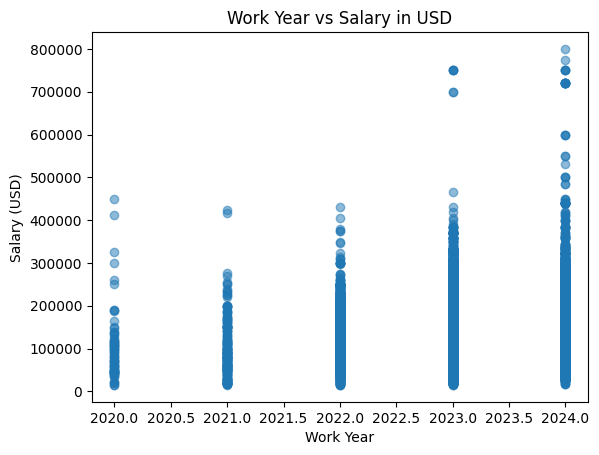

In [23]:
plt.scatter(
    df['work_year'],
    df['salary_in_usd'],
    alpha=0.5
)

plt.title('Work Year vs Salary in USD')
plt.xlabel('Work Year')
plt.ylabel('Salary (USD)')

plt.show()

**Task 10 — Distribution.** Plot the distribution of `salary_in_usd`. Does it look approximately normal, skewed, or something else? Are there extreme values?

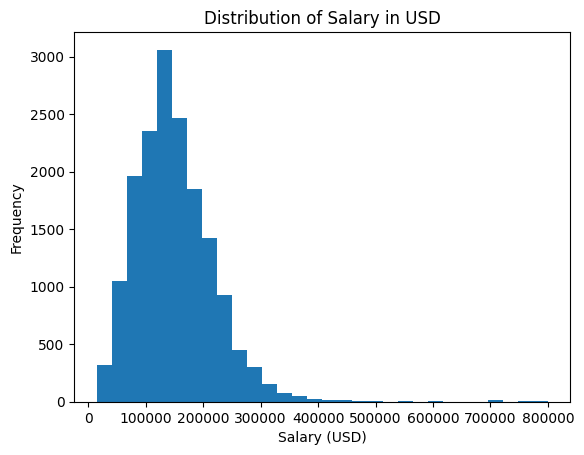

In [24]:
import matplotlib.pyplot as plt

# Plot salary distribution
plt.hist(df['salary_in_usd'], bins=30)

# Add title and labels
plt.title('Distribution of Salary in USD')
plt.xlabel('Salary (USD)')
plt.ylabel('Frequency')

plt.show()

In [25]:
# Find the minimum and maximum salaries
print("Minimum salary:", df['salary_in_usd'].min())
print("Maximum salary:", df['salary_in_usd'].max())

# Calculate quartiles
print(df['salary_in_usd'].describe())

Minimum salary: 15000
Maximum salary: 800000
count     16534.000000
mean     149686.777973
std       68505.293156
min       15000.000000
25%      101125.000000
50%      141300.000000
75%      185900.000000
max      800000.000000
Name: salary_in_usd, dtype: float64


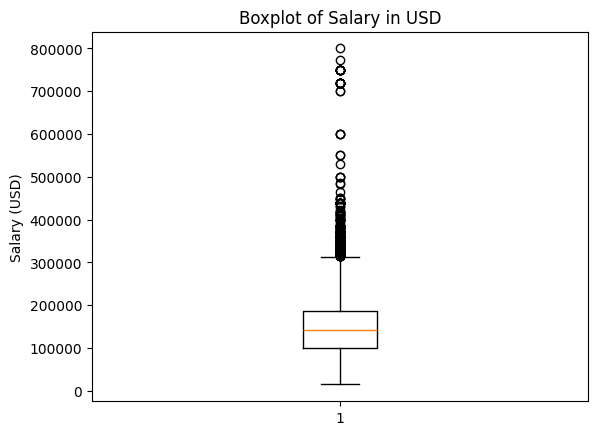

In [26]:
plt.boxplot(df['salary_in_usd'])

plt.title('Boxplot of Salary in USD')
plt.ylabel('Salary (USD)')

plt.show()

**Task 11 — Pairwise relationships.** Visualize pairwise relationships among `salary_in_usd`, `work_year`, and `remote_ratio`, including distributions of the individual variables.

Try to compare the variables in one combined visualization. What relationships or patterns do you notice?

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

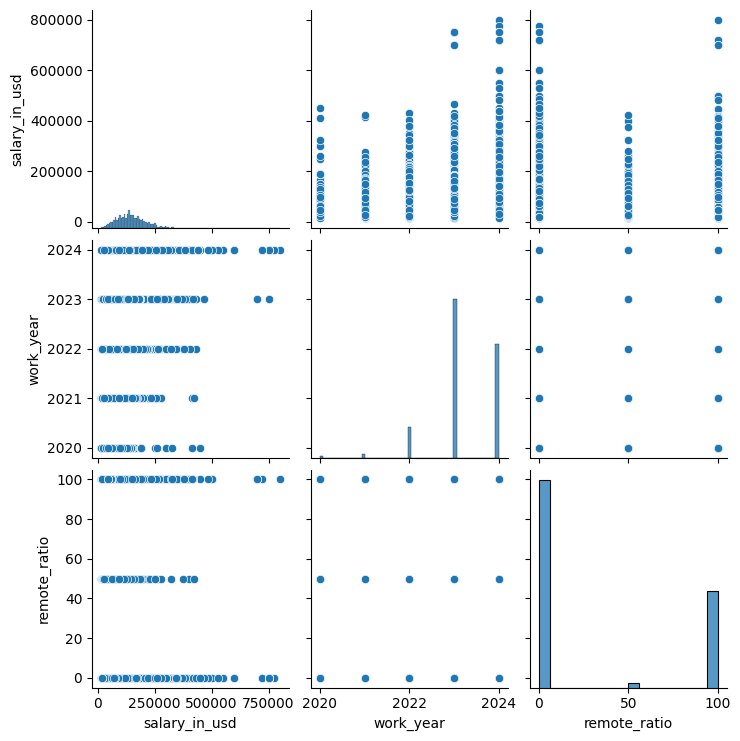

In [28]:
# Select the three variables
selected_columns = ['salary_in_usd', 'work_year', 'remote_ratio']

# Create pairplot
sns.pairplot(df[selected_columns])

plt.show()

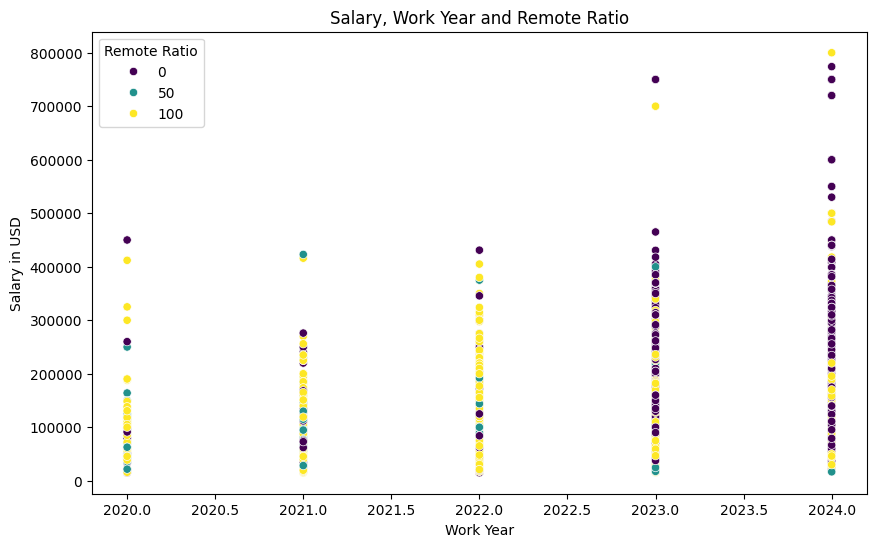

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create combined scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='work_year',
    y='salary_in_usd',
    hue='remote_ratio',
    palette='viridis'
)

# Add title and labels
plt.title('Salary, Work Year and Remote Ratio')
plt.xlabel('Work Year')
plt.ylabel('Salary in USD')

plt.legend(title='Remote Ratio')
plt.show()

**Task 12 — Remove a column.** Remove the original-currency `salary` column while retaining `salary_in_usd`, then inspect the updated DataFrame. Why might you choose to keep one salary column rather than both?

In [30]:
# Remove the original salary column
df = df.drop(columns=['salary'])

In [31]:
# Display the first five rows
df.head()

,work_year,experience_level,employment_type,job_title,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,USD,190000,US,0,US,M


In [32]:
print(df.columns)

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')


In [33]:
print(df.shape)

(16534, 10)


**Reflection.** What have you learned about the salary dataset? Which additional checks or visualizations would be useful before building a machine learning model?

Well done!

The dataset contains information about salaries in the data science and technology job market.

The first five records show variables such as:
- Work year
- Experience level
- Employment type
- Job title
- Salary and salary currency
- Salary in USD
- Employee residence
- Remote working ratio
- Company location and size

Data type	Number of columns
Integer (int64)	4
Object (categorical/text)	7
Total	11

All 16,534 records contain values in every column.

This means there are no missing values in the original dataset.

Every column has zero missing values and a missing-data percentage of 0%.

Interpretation: Missing-data imputation is not currently necessary. However, it is still important to check for invalid or incorrectly recorded values, since a dataset can contain errors even when there are no missing values.


Category	Number
Exact duplicate rows	6,421
Non-duplicate rows	10,113
Total rows	16,534

Approximately 38.84% of the rows are duplicates according to Pandas' exact-row duplicate check.

Interpretation:

This is a substantial proportion and deserves further investigation.

However, identical records are not automatically errors. Two different employees could have identical job titles, salaries, experience levels and locations.

I would investigate whether these records represent genuine observations or repeated entries before removing them.

Interpretation of the summary table:
- The average salary is approximately $149,687.
- The median salary is $141,300.
- The mean is higher than the median, suggesting that a number of high salaries are pulling the average upwards.
- The standard deviation of approximately $68,505 indicates considerable variation in salaries.

Executive-level employees have the highest average salary, at approximately $195,264.

Interpretation:

There is a clear positive relationship between experience level and average salary. As the level of professional experience increases, the average salary also increases.

This suggests that seniority and experience are important factors associated with salary differences.

Interpretation of the scatterplot:
- Average salaries generally increased between 2021 and 2023.
- There was a slight decrease in average salary in 2024.
- The observations are concentrated in 2023 and 2024.
- Overlapping points are likely because multiple employees share the same work year and similar salary values.
An important limitation is that the number of observations differs significantly across years. Therefore, the apparent salary trend should not automatically be interpreted as an overall increase in salaries across the entire industry.

Using the interquartile range method:
- Lower quartile: $101,125
- Upper quartile: $185,900
- Upper outlier threshold: $313,062.50
- Number of observations above this threshold: 283
Interpretation:

The salary distribution is not approximately normal. It is right-skewed, with most salaries concentrated towards the lower and middle portions of the distribution and a smaller number of very high salaries.

There are 283 observations above the conventional upper IQR threshold. These should be investigated rather than automatically deleted, as some may represent genuine high-paying positions.

Variable relationship	Correlation
Salary and work year	+0.078
Salary and remote ratio	-0.057
Work year and remote ratio	-0.200

Interpretation:
- Salary and work year have a very weak positive linear relationship.
- Salary and remote ratio have a very weak negative linear relationship.
- Work year and remote ratio have a weak negative relationship.
This suggests that neither work year nor remote ratio, on its own, has a strong linear relationship with salary.

One interesting observation is that the correlation between work year and salary is weak, despite the increase in average salaries between 2021 and 2023.

This could be influenced by differences in job roles, experience levels and the composition of the dataset across years.

This means the dataset contains considerably more observations for employees with a 0% remote ratio than for hybrid workers.
Employees with a 0% remote ratio have the highest average salary, followed by fully remote employees. Hybrid employees have a substantially lower average.

However, the hybrid category contains only 249 observations, compared with 11,118 for the 0% category. This imbalance makes the comparison less reliable.

It would be interesting to investigate whether remote-working arrangements are associated with salary differences after controlling for experience, job title and geographical location.

- 16,534 rows
- 10 columns
- salary_in_usd retained
- Original salary removed
The updated dataset has three numerical columns and seven categorical/text columns.

Why remove the original salary column?

The original salary column contains different currencies, which makes comparisons misleading. Retaining salary in USD provides a consistent measurement across countries.

It also simplifies subsequent analysis by reducing unnecessary variables.

1. Salary is influenced by experience level.

Executive-level employees have the highest average salary, while entry-level employees have the lowest. This suggests that professional experience and seniority are important factors associated with salary differences.

2. Salary distributions are positively skewed.

The mean salary is higher than the median, indicating that some particularly high salaries influence the average. The presence of 283 observations above the upper IQR threshold further supports the need to investigate extreme values.

3. Salary patterns change across work years.

Average salaries increased between 2021 and 2023, followed by a slight decline in 2024. However, the distribution of observations across years is uneven, so further investigation is necessary before drawing conclusions about salary growth.

4. Remote working does not show a strong linear relationship with salary.

The correlation between remote ratio and salary is approximately -0.057. However, the average salary differences across remote-working categories suggest that there may be patterns worth investigating further.

5. Data quality requires further investigation.

Although there are no missing values, approximately 38.84% of the records are exact duplicates according to the initial duplicate count. This is potentially significant and should be investigated before building a machine learning model.

Reflection:
## Reflection on Exploratory Data Analysis

Through the exploratory data analysis, I developed a better understanding of the salary dataset and the factors that may influence salary differences within the data science and technology industry.

The dataset initially contained 16,534 records and 11 columns, covering variables such as work year, experience level, employment type, job title, salary, employee residence and company location. One of the first observations was that the dataset contained no missing values, meaning that imputation was not immediately necessary. However, I identified 6,421 exact duplicate rows, representing approximately 38.84% of the dataset. This highlighted the importance of investigating data quality before proceeding with machine learning, as duplicate records could potentially introduce bias into the model if they represent repeated observations rather than genuine employees.

The descriptive statistics revealed considerable variation in salaries, with an average salary of approximately $149,687 and a median of $141,300. The difference between these values suggested a positively skewed distribution, which was supported by the salary distribution analysis. I also identified 283 observations above the upper interquartile range threshold. These extreme values could represent genuine high-paying positions, so they would require further investigation rather than automatic removal.

One particularly interesting finding was the relationship between experience level and salary. Executive-level employees had the highest average salary of approximately $195,264, compared with approximately $92,327 for entry-level employees. This suggests that professional experience and seniority are important factors associated with salary differences. The analysis of work year also revealed that average salaries generally increased between 2021 and 2023, before experiencing a slight decrease in 2024. However, the number of observations varied considerably across years, which means that this pattern should be interpreted cautiously.

I also explored the relationship between salary and remote working arrangements. Although the correlation between salary and remote ratio was weak, the average salaries differed across the three remote-working categories. Hybrid employees had a considerably lower average salary than employees in the other categories. However, the hybrid category contained substantially fewer observations, making it difficult to establish whether this difference represents a genuine relationship. This demonstrated the importance of considering sample sizes and potential imbalances when interpreting visualisations.

Another important data preparation decision was removing the original salary column while retaining salary in USD. Since the original salary values could be expressed in different currencies, comparing them directly would be misleading. Using salary in USD provides a standardised measurement and makes comparisons across geographical locations more meaningful.

Overall, the EDA demonstrated that salary differences may be associated with several factors, including experience level, work year, job title, geographical location and remote working arrangements. However, the relationships identified through these visualisations and descriptive statistics do not establish causation.

Before developing a machine learning model, I would conduct further investigations into duplicate records, outliers and categorical imbalances. I would also explore salary distributions across job titles, geographical locations and company sizes using boxplots and other visualisations. Additionally, categorical variables would need to be appropriately encoded, and the data would need to be divided into training and testing sets.

These steps would help ensure that the dataset is sufficiently reliable and appropriately prepared for machine learning, ultimately improving the interpretability and potential performance of the predictive model.